In [1]:
from pathlib import Path

import pandas as pd

csv_path = Path("data/processed/wifi_localization.csv")
if not csv_path.is_file():
    csv_path = Path("../../data/processed/wifi_localization.csv")

df = pd.read_csv(csv_path)

print("Kích thước dữ liệu:", df.shape)
print("Số mẫu theo phòng:")
print(df.iloc[:, -1].value_counts().sort_index())

Kích thước dữ liệu: (2000, 8)
Số mẫu theo phòng:
Room
1    500
2    500
3    500
4    500
Name: count, dtype: int64


In [2]:
from sklearn.model_selection import StratifiedKFold

X = df.drop(columns="Room")  # 7 cột tín hiệu WiFi
y = df["Room"]               # Nhãn phòng cần dự đoán

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

train_idx, val_idx = next(cv.split(X, y))

print("Kích thước X:", X.shape)
print("Fold đầu:", len(train_idx), "mẫu train,", len(val_idx), "mẫu validation")
print("Số mẫu mỗi phòng trong tập validation:")
print(y.iloc[val_idx].value_counts().sort_index())

Kích thước X: (2000, 7)
Fold đầu: 1800 mẫu train, 200 mẫu validation
Số mẫu mỗi phòng trong tập validation:
Room
1    50
2    50
3    50
4    50
Name: count, dtype: int64


In [3]:
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

knn_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier()),
])

knn_param_grid = {
    "knn__n_neighbors": [1, 3, 5, 7, 9, 11, 15],
    "knn__weights": ["uniform", "distance"],
    "knn__p": [1, 2],
}

knn_search = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=knn_param_grid,
    scoring="f1_macro",
    cv=cv,
    verbose=1,
)

knn_search.fit(X, y)

knn_f1_std = knn_search.cv_results_["std_test_score"][knn_search.best_index_]

print("Tham số KNN tốt nhất:", knn_search.best_params_)
print(f"F1-macro trung bình: {knn_search.best_score_:.4f}")
print(f"Độ lệch chuẩn qua 10 fold: {knn_f1_std:.4f}")

Fitting 10 folds for each of 28 candidates, totalling 280 fits
Tham số KNN tốt nhất: {'knn__n_neighbors': 3, 'knn__p': 2, 'knn__weights': 'uniform'}
F1-macro trung bình: 0.9875
Độ lệch chuẩn qua 10 fold: 0.0090


In [4]:
from sklearn.svm import SVC

svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="rbf")),
])

svm_param_grid = {
    "svm__C": [0.1, 1, 10, 100],
    "svm__gamma": ["scale", 0.001, 0.01, 0.1, 1],
}

svm_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=svm_param_grid,
    scoring="f1_macro",
    cv=cv,
    verbose=1,
)

svm_search.fit(X, y)

svm_f1_std = svm_search.cv_results_["std_test_score"][svm_search.best_index_]

print("Tham số SVM tốt nhất:", svm_search.best_params_)
print(f"F1-macro trung bình: {svm_search.best_score_:.4f}")
print(f"Độ lệch chuẩn qua 10 fold: {svm_f1_std:.4f}")

Fitting 10 folds for each of 20 candidates, totalling 200 fits
Tham số SVM tốt nhất: {'svm__C': 1, 'svm__gamma': 1}
F1-macro trung bình: 0.9835
Độ lệch chuẩn qua 10 fold: 0.0071


In [5]:
summary = pd.DataFrame({
    "Mô hình": ["KNN", "SVM-RBF"],
    "F1-macro trung bình": [knn_search.best_score_, svm_search.best_score_],
    "Độ lệch chuẩn": [knn_f1_std, svm_f1_std],
})

summary.round(4)

,Mô hình,F1-macro trung bình,Độ lệch chuẩn
0,KNN,0.9875,0.0090
1,SVM-RBF,0.9835,0.0071


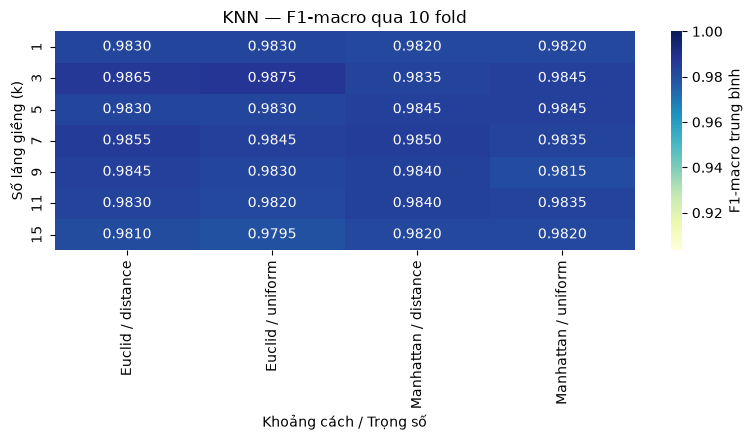

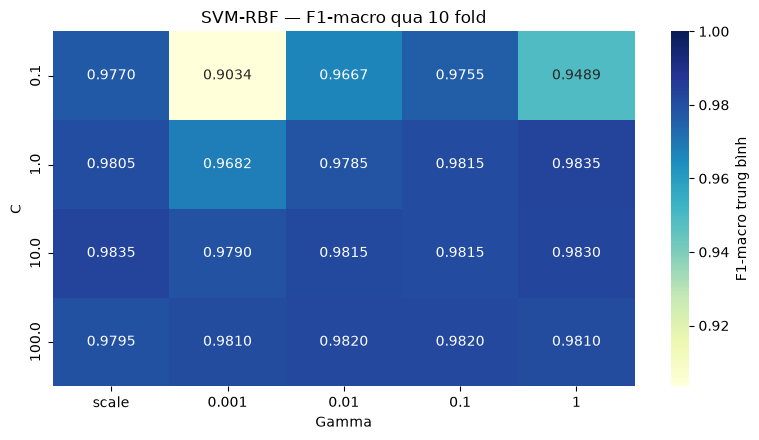

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

knn_results = pd.DataFrame(knn_search.cv_results_)
knn_results["distance_weights"] = (
    knn_results["param_knn__p"].map({1: "Manhattan", 2: "Euclid"})
    + " / " + knn_results["param_knn__weights"].astype(str)
)
knn_heatmap = knn_results.pivot(
    index="param_knn__n_neighbors",
    columns="distance_weights",
    values="mean_test_score",
)

svm_results = pd.DataFrame(svm_search.cv_results_)
svm_results["gamma"] = svm_results["param_svm__gamma"].astype(str)
svm_heatmap = svm_results.pivot(
    index="param_svm__C",
    columns="gamma",
    values="mean_test_score",
).reindex(columns=["scale", "0.001", "0.01", "0.1", "1"])

figure_dir = csv_path.resolve().parents[2] / "figures" / "classification"
figure_dir.mkdir(parents=True, exist_ok=True)

min_score = min(knn_heatmap.min().min(), svm_heatmap.min().min())

for scores, model, x_label, y_label, filename in [
    (knn_heatmap, "KNN", "Khoảng cách / Trọng số", "Số láng giềng (k)", "knn_heatmap.png"),
    (svm_heatmap, "SVM-RBF", "Gamma", "C", "svm_heatmap.png"),
]:
    fig, ax = plt.subplots(figsize=(8, 4.5))
    sns.heatmap(
        scores, annot=True, fmt=".4f", cmap="YlGnBu",
        vmin=min_score, vmax=1.0, ax=ax,
        cbar_kws={"label": "F1-macro trung bình"},
    )
    ax.set(title=f"{model} — F1-macro qua 10 fold", xlabel=x_label, ylabel=y_label)
    fig.tight_layout()
    fig.savefig(figure_dir / filename, dpi=180)
    plt.show()


## Nhận xét kết quả KNN và SVM-RBF

Hai mô hình sử dụng 7 đặc trưng tín hiệu WiFi và được đánh giá trên cùng
10 fold phân tầng. StandardScaler được đặt trong Pipeline để các tham số
chuẩn hóa của mỗi fold chỉ được tính từ tập huấn luyện.

- **KNN** đạt F1-macro trung bình **0,9875**, với độ lệch chuẩn **0,0090**.
  Cấu hình được chọn sử dụng 3 láng giềng, khoảng cách Euclid và cho mỗi
  láng giềng trọng số bằng nhau.
- **SVM-RBF** đạt F1-macro trung bình **0,9835**, với độ lệch chuẩn **0,0071**.
  GridSearchCV chọn cấu hình `C=1`, `gamma=1`.

Trong lần đánh giá này, KNN có F1-macro trung bình cao hơn 0,0040.
SVM-RBF có điểm ít dao động hơn giữa các fold. Các điểm trên được tính
từ 10 fold dùng để chọn siêu tham số.